# Lab 2A: Building a Simple Neural Network

**Course:** Computer Vision (0135326)
**Instructor:** Dr. Akram Fatayer

## Learning Objectives
By the end of this lab, you will be able to:
1. Understand the basic structure of a PyTorch project.
2. Load and preprocess a standard image dataset (MNIST).
3. Define a Multi-Layer Perceptron (MLP) architecture.
4. Implement a training loop with a loss function and optimizer.
5. Evaluate the model's performance on unseen data.

## Prerequisites
This lab assumes you have completed Lab 1 and are comfortable with basic Python and NumPy. We will be using **PyTorch**, the industry standard for Deep Learning research.

## 1. Setup and Data Loading

First, let's import the necessary libraries. PyTorch provides `torchvision`, which makes it incredibly easy to download and load standard datasets like MNIST (a dataset of handwritten digits).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Set device to GPU if available, otherwise CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


### Loading the MNIST Dataset

We need to transform the images into PyTorch tensors and normalize them. Normalization helps the neural network train faster and more stably.

In [2]:
# Define transformations: Convert to tensor and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # Mean and Std Dev for normalization
])

# Download and load the training data
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

# Download and load the test data
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.75MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.11MB/s]


Let's visualize a few images from the dataset to understand what we're working with.

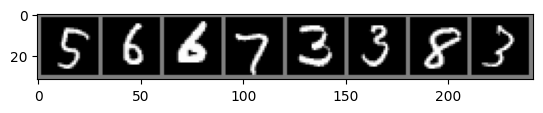

Labels: 5 6 6 7 3 3 8 3 8


In [15]:
def imshow(img):
    img = img / 2 + 0.5     # Unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)), cmap='gray')
    plt.show()

# Get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Show images
imshow(torchvision.utils.make_grid(images[:8]))
# Print labels
print('Labels:', ' '.join(f'{labels[j].item()}' for j in range(8)))

## 2. Defining the Neural Network Architecture

Now we will define our Multi-Layer Perceptron (MLP). In PyTorch, we do this by creating a class that inherits from `nn.Module`.

**Exercise 1: Define the Network Layers**

Complete the `__init__` and `forward` methods below.
- The input images are 28x28 pixels, so they need to be flattened into a 1D vector of size 784.
- Create a hidden layer with 128 neurons and a ReLU activation function.
- Create an output layer with 10 neurons (one for each digit 0-9).

In [4]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super(SimpleMLP, self).__init__()
        self.fc1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
         # Flatten the image from (batch_size, 1, 28, 28) to (batch_size, 784)
        x = x.view(-1, 28 * 28)

        # Pass x through the layers
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

# Instantiate the model and move it to the device (GPU/CPU)
model = SimpleMLP().to(device)
print(model)

SimpleMLP()


## 3. Training the Model

To train the model, we need two things:
1. **Loss Function:** Measures how far off our predictions are from the true labels. For classification, we use Cross-Entropy Loss.
2. **Optimizer:** Updates the model's weights based on the gradients calculated during backpropagation. We'll use Stochastic Gradient Descent (SGD).

In [5]:
# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

ValueError: optimizer got an empty parameter list

**Exercise 2: The Training Loop**

The training loop is the heart of deep learning. For each batch of data, we must:
1. Zero the gradients.
2. Perform a forward pass (get predictions).
3. Calculate the loss.
4. Perform a backward pass (calculate gradients).
5. Update the weights (optimizer step).

Complete the missing steps in the training loop below.

In [ ]:
epochs = 5

for epoch in range(epochs):  # Loop over the dataset multiple times
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0].to(device), data[1].to(device)

        # TODO: Step 1 - Zero the parameter gradients
        # ...

        # TODO: Step 2 - Forward pass
        # outputs = ...

        # TODO: Step 3 - Calculate loss
        # loss = ...

        # TODO: Step 4 - Backward pass
        # ...

        # TODO: Step 5 - Optimize (update weights)
        # ...

        # Print statistics (assuming you named your loss variable 'loss')
        # running_loss += loss.item()
        # if i % 300 == 299:    # Print every 300 mini-batches
        #     print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 300:.3f}')
        #     running_loss = 0.0

print('Finished Training')

## 4. Evaluating the Model

Now that the model is trained, we need to see how well it performs on data it has never seen before (the test set).

In [ ]:
correct = 0
total = 0
# Since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        inputs, labels = data[0].to(device), data[1].to(device)

        # Calculate outputs by running images through the network
        outputs = model(inputs)

        # The class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

**Exercise 3: Reflection**

In the cell below, write a brief reflection (1-2 paragraphs) answering the following questions:
1. What accuracy did your model achieve? Is this good for a simple MLP on MNIST?
2. What happens if you change the learning rate (e.g., to 0.1 or 0.001) or the number of hidden neurons? Try it and describe the results.

*Write your reflection here...*